In [131]:
from itertools import product
from time import perf_counter

import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [100]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [101]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

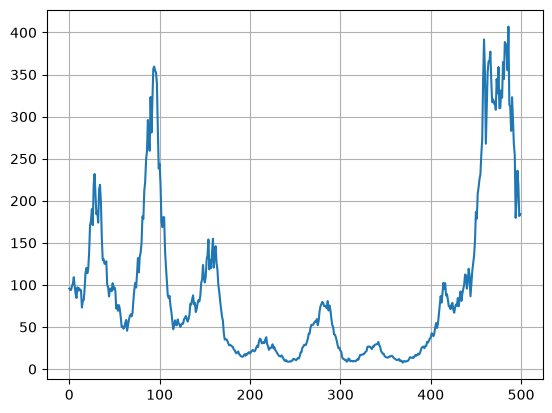

In [102]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [103]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

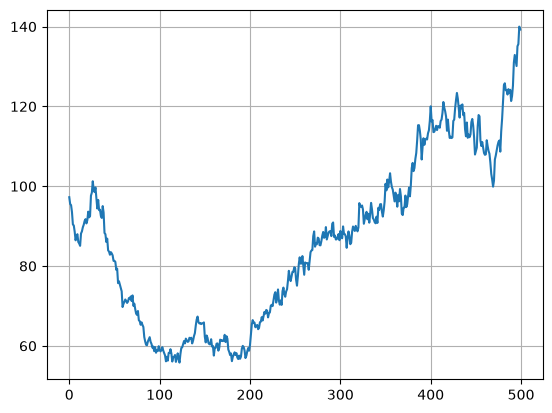

In [104]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [105]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

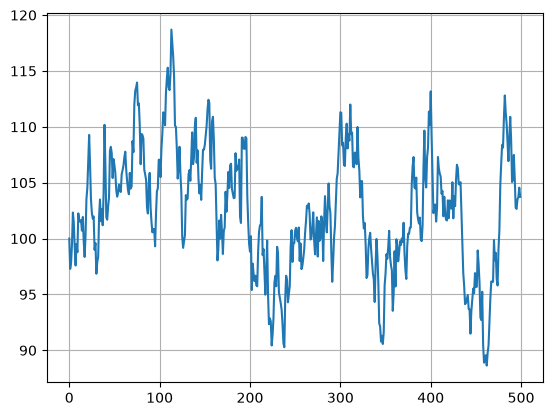

In [106]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [107]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

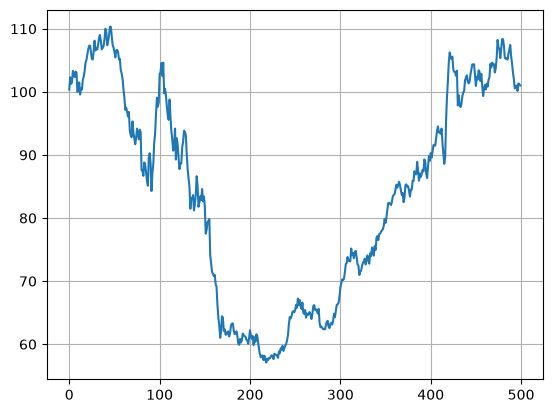

In [108]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [109]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [110]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

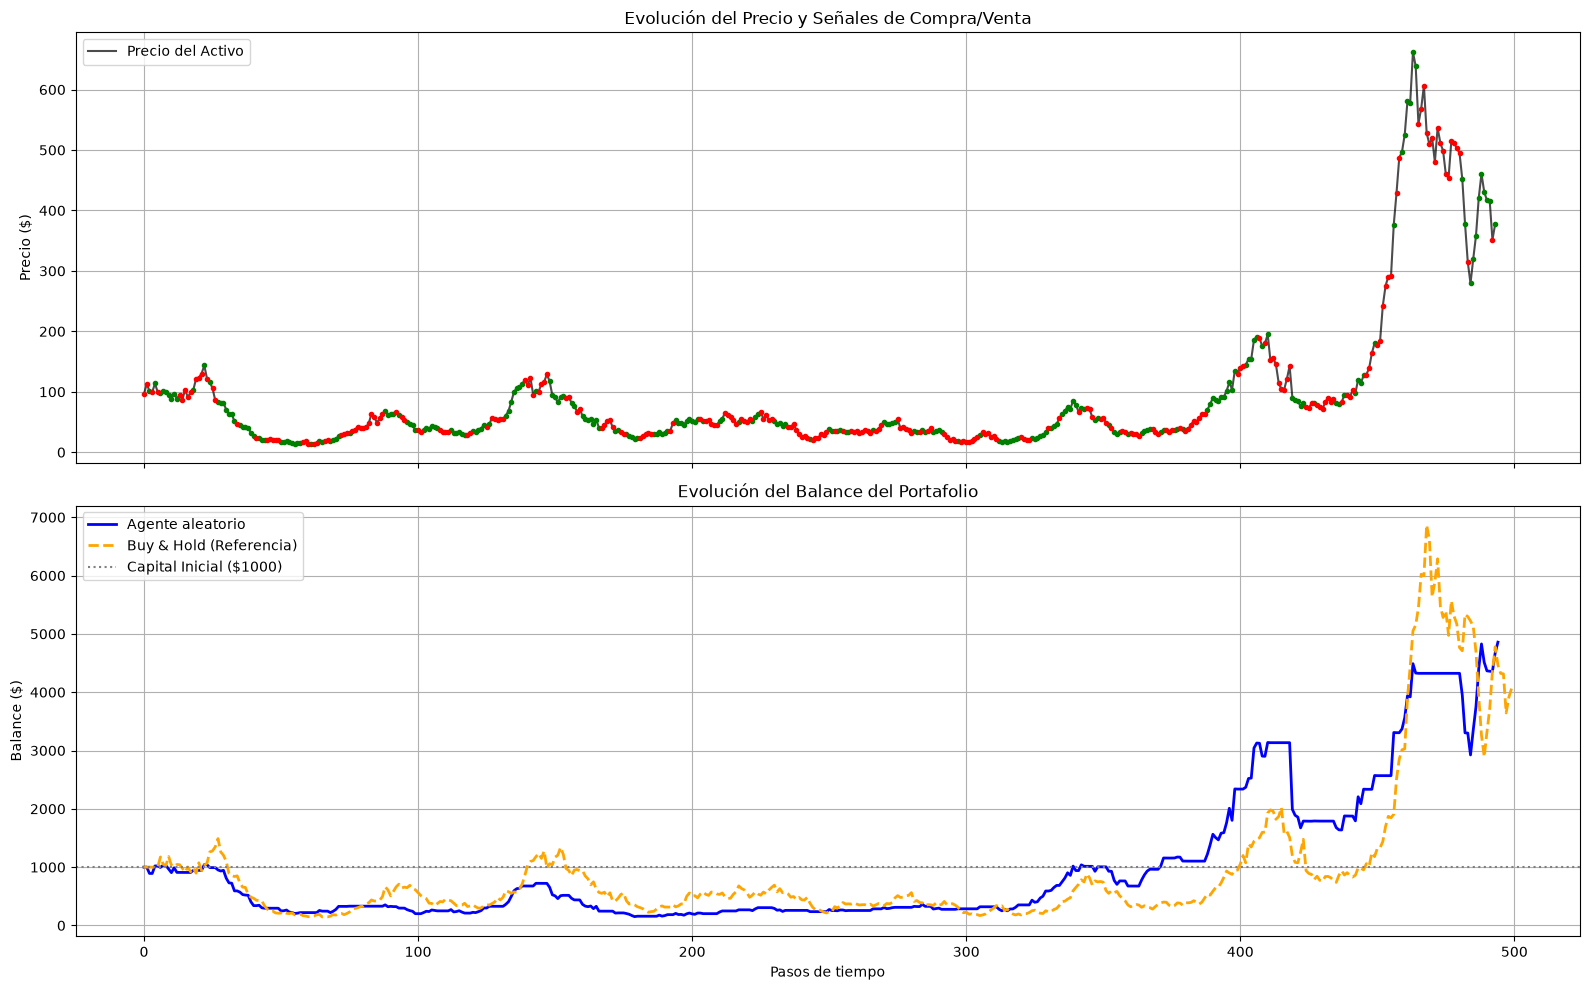

In [111]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *Q-Learning* y *Sarsa*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **29/10/2026**, a las **23:59**.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

# Q-Learning 

## Discretización del espacio de estados

Para aplicar Q-learning tabular necesitamos convertir la componente continua de la observación, la tendencia, en un número finito de estados. Aunque el entorno limita esta variable al intervalo $[-1, 1]$, su definición como diferencia relativa respecto a una media móvil hace que, en condiciones normales, la mayoría de sus valores se concentren cerca de cero. Una partición uniforme de todo el intervalo dedicaría muchos estados a tendencias extremas que se visitarían muy pocas veces y ofrecería poca resolución en la zona más frecuente.

Por ese motivo se utiliza una discretización no uniforme: los intervalos son estrechos alrededor de cero y progresivamente más anchos al alejarnos de él. Los valores inferiores a $-0.10$ y superiores o iguales a $0.10$ se agrupan en dos estados extremos. Así obtenemos 14 estados de tendencia, que combinados con las dos posiciones posibles (sin activo o con activo) producen 28 estados discretos. Con tres acciones, la futura tabla Q tendrá dimensiones $14 \times 2 \times 3$. Esta división es un punto de partida interpretable; posteriormente conviene comprobar la distribución observada y ajustar los límites si algunos estados apenas se visitan.

In [112]:
class StateDiscretizer:
    """Convierte la observación continua del entorno en un estado tabular."""

    def __init__(self):
        # Trece fronteras internas generan catorce estados de tendencia.
        self.trend_bins = np.array(
            [
                -0.10, -0.05, -0.03, -0.02, -0.01, -0.005,
                0.0,
                0.005, 0.01, 0.02, 0.03, 0.05, 0.10,
            ],
            dtype=np.float32,
        )

    @property
    def n_trend_states(self):
        return len(self.trend_bins) + 1

    @property
    def n_position_states(self):
        return 2

    @property
    def state_shape(self):
        return self.n_trend_states, self.n_position_states

    def discretize(self, observation):
        """Devuelve el estado (intervalo_de_tendencia, posicion)."""
        trend, position = observation
        trend_state = int(np.digitize(trend, self.trend_bins))
        position_state = int(position)
        return trend_state, position_state

In [113]:
def initialize_q_table(discretizer, n_actions):
    """Inicializa Q[estado_tendencia, posicion, accion] a cero."""
    if n_actions <= 0:
        raise ValueError("n_actions debe ser un entero positivo")

    return np.zeros(
        (*discretizer.state_shape, n_actions),
        dtype=np.float32,
    )


discretizer = StateDiscretizer()
n_actions = env.action_space.n
q_table = initialize_q_table(discretizer, n_actions)

print(f"Dimensiones de la tabla Q: {q_table.shape}")

Dimensiones de la tabla Q: (14, 2, 3)


## Entrenamiento con Q-learning

Además de la tasa de exploración $\epsilon$ y el factor de descuento $\gamma$, Q-learning necesita una tasa de aprendizaje $\alpha$, que determina cuánto modifica cada transición el valor Q actual. La exploración comienza con el valor indicado por `epsilon` y disminuye después de cada episodio mediante `epsilon_decay`, sin bajar de `min_epsilon`.

En cada paso, la política $\epsilon$-greedy selecciona la acción mediante la siguiente regla:

$$
a_t = \begin{cases}
a \sim \operatorname{Uniforme}(\mathcal{A}), & \text{con probabilidad } \epsilon, \\
\displaystyle \arg\max_{a \in \mathcal{A}} Q(s_t,a), & \text{con probabilidad } 1-\epsilon.
\end{cases}
$$

Por tanto, con probabilidad $\epsilon$ el agente explora eligiendo cualquiera de las tres acciones al azar y, con probabilidad $1-\epsilon$, explota el conocimiento adquirido escogiendo una acción con el mayor valor Q. Si varias acciones comparten el máximo, el código desempata aleatoriamente entre ellas para evitar favorecer siempre la acción con el índice más bajo.

La actualización que realiza Q-learning después de observar una transición $(s_t, a_t, r_{t+1}, s_{t+1})$ es:

$$
Q(s_t,a_t) \leftarrow Q(s_t,a_t) + \alpha \left[r_{t+1} + \gamma \max_{a'} Q(s_{t+1},a') - Q(s_t,a_t)\right]
$$

Aquí, $Q(s_t,a_t)$ es la estimación actual del valor de ejecutar la acción $a_t$ en el estado $s_t$; $r_{t+1}$ es la recompensa recibida; $\max_{a'}Q(s_{t+1},a')$ es el valor de la mejor acción conocida en el estado siguiente; $\alpha$ controla cuánto aprendemos de la transición y $\gamma$ cuánto valoramos las recompensas futuras. La expresión entre corchetes es el error temporal o *TD error*. Si la transición termina el episodio, el objetivo es únicamente $r_{t+1}$, porque no existe un estado futuro cuyo valor debamos añadir.

La tabla Q se inicializa una sola vez. En cada episodio se genera una serie de precios nueva con la función elegida y se crea un entorno nuevo, pero el conocimiento acumulado en Q se conserva. El historial devuelto permitirá analizar posteriormente la recompensa, el balance y la evolución de $\epsilon$.

In [114]:
def select_epsilon_greedy_action(q_table, state, action_space, epsilon, rng):
    """Selecciona una acción exploratoria o una de las mejores acciones conocidas."""
    if rng.random() < epsilon:
        return action_space.sample()

    q_values = q_table[state]
    best_actions = np.flatnonzero(q_values == q_values.max())
    return int(rng.choice(best_actions))


def train_q_learning(
    price_generator,
    n_episodes,
    n_steps,
    alpha=0.1,
    gamma=0.99,
    epsilon=1.0,
    epsilon_decay=0.995,
    min_epsilon=0.05,
    seed=None,
):
    """Entrena una tabla Q usando una serie de precios nueva en cada episodio."""
    if n_episodes <= 0:
        raise ValueError("n_episodes debe ser un entero positivo")
    if n_steps < 7:
        raise ValueError("n_steps debe ser al menos 7")
    if not 0 < alpha <= 1:
        raise ValueError("alpha debe pertenecer a (0, 1]")
    if not 0 <= gamma <= 1:
        raise ValueError("gamma debe pertenecer a [0, 1]")
    if not 0 <= min_epsilon <= epsilon <= 1:
        raise ValueError("se requiere 0 <= min_epsilon <= epsilon <= 1")
    if not 0 < epsilon_decay <= 1:
        raise ValueError("epsilon_decay debe pertenecer a (0, 1]")

    if seed is not None:
        # Los generadores definidos en el notebook usan np.random globalmente.
        np.random.seed(seed)

    rng = np.random.default_rng(seed)
    discretizer = StateDiscretizer()
    q_table = None
    current_epsilon = epsilon

    episode_rewards = []
    final_balances = []
    epsilon_history = []

    for episode in range(n_episodes):
        prices = price_generator(n_steps=n_steps)
        env = SimpleTradingEnv(prices)
        observation, _ = env.reset(
            seed=None if seed is None else seed + episode
        )
        if seed is not None:
            env.action_space.seed(seed + episode)

        if q_table is None:
            q_table = initialize_q_table(discretizer, env.action_space.n)

        terminated = False
        truncated = False
        total_reward = 0.0

        while not (terminated or truncated):
            state = discretizer.discretize(observation)
            action = select_epsilon_greedy_action(
                q_table, state, env.action_space, current_epsilon, rng
            )

            next_observation, reward, terminated, truncated, info = env.step(action)
            next_state = discretizer.discretize(next_observation)
            state_action = (*state, action)

            if terminated or truncated:
                target = reward
            else:
                target = reward + gamma * np.max(q_table[next_state])

            q_table[state_action] += alpha * (
                target - q_table[state_action]
            )

            observation = next_observation
            total_reward += reward

        episode_rewards.append(total_reward)
        final_balances.append(info["balance"])
        epsilon_history.append(current_epsilon)
        current_epsilon = max(min_epsilon, current_epsilon * epsilon_decay)

    history = {
        "initial_balance": env.initial_balance,
        "episode_rewards": np.asarray(episode_rewards),
        "final_balances": np.asarray(final_balances),
        "epsilon": np.asarray(epsilon_history),
    }

    return q_table, discretizer, history

## Selección de hiperparámetros

### 1. Crear un conjunto de validación fijo

El primer paso es generar un banco de series que no se utilizará para actualizar la tabla Q. La semilla hace que todas las configuraciones de hiperparámetros se evalúen exactamente sobre los mismos mercados, evitando que una configuración resulte favorecida por haber recibido series más sencillas. Este conjunto debe generarse con una semilla distinta de la utilizada durante el entrenamiento y del futuro conjunto de test.

La función guarda y restaura el estado global de NumPy porque los generadores de precios definidos anteriormente utilizan `np.random` directamente. De este modo, crear el conjunto de validación no altera accidentalmente la secuencia aleatoria del resto del notebook.

In [115]:
def generate_price_dataset(
    price_generator,
    n_series,
    n_steps,
    seed=2026,
):
    """Genera un conjunto reproducible de series sin alterar el RNG global."""
    if n_series <= 0:
        raise ValueError("n_series debe ser un entero positivo")
    if n_steps < 7:
        raise ValueError("n_steps debe ser al menos 7")

    random_state = np.random.get_state()
    np.random.seed(seed)

    try:
        dataset = []
        for _ in range(n_series):
            prices = np.asarray(
                price_generator(n_steps=n_steps),
                dtype=np.float64,
            )
            if prices.shape != (n_steps,):
                raise ValueError(
                    "price_generator debe devolver una serie de longitud n_steps"
                )
            dataset.append(prices.copy())
    finally:
        np.random.set_state(random_state)

    return tuple(dataset)

### 2. Evaluar una tabla Q sin modificarla

Durante la validación usamos una política voraz ($\epsilon=0$): el agente selecciona una acción con valor Q máximo y solo utiliza aleatoriedad para desempatar cuando varias acciones tienen el mismo valor. A diferencia del entrenamiento, aquí no se aplica la ecuación de actualización, por lo que la tabla Q permanece intacta.

Para cada serie guardamos la recompensa acumulada, el balance final y el retorno $R=(B_{final}/B_{inicial})-1$. El retorno medio servirá más adelante como puntuación principal para comparar configuraciones, mientras que su desviación típica permitirá detectar estrategias con resultados inestables.

In [116]:
def evaluate_policy_on_dataset(policy, price_dataset, seed=0):
    """Evalúa cualquier política sobre un conjunto fijo de series."""
    if len(price_dataset) == 0:
        raise ValueError("price_dataset no puede estar vacío")

    episode_rewards = []
    final_balances = []
    returns = []
    action_counts = []
    trade_counts = []

    for episode, price_series in enumerate(price_dataset):
        prices = np.asarray(price_series, dtype=np.float64)
        if prices.ndim != 1 or len(prices) < 7:
            raise ValueError("cada serie debe ser un vector con al menos 7 precios")
        if not np.all(np.isfinite(prices)) or np.any(prices <= 0):
            raise ValueError("todos los precios deben ser finitos y positivos")

        env = SimpleTradingEnv(prices)
        observation, _ = env.reset(seed=seed + episode)
        rng = np.random.default_rng(seed + episode)
        episode_action_counts = np.zeros(
            env.action_space.n, dtype=np.int64
        )
        episode_trade_count = 0
        total_reward = 0.0
        terminated = False
        truncated = False

        while not (terminated or truncated):
            previous_position = env.position
            action = int(policy(observation, env, rng))
            if not env.action_space.contains(action):
                raise ValueError(f"la política devolvió una acción inválida: {action}")
            episode_action_counts[action] += 1
            observation, reward, terminated, truncated, info = env.step(action)
            episode_trade_count += int(env.position != previous_position)
            total_reward += reward

        final_balance = info["balance"]
        episode_return = final_balance / env.initial_balance - 1.0
        episode_rewards.append(total_reward)
        final_balances.append(final_balance)
        returns.append(episode_return)
        action_counts.append(episode_action_counts)
        trade_counts.append(episode_trade_count)

    episode_rewards = np.asarray(episode_rewards)
    final_balances = np.asarray(final_balances)
    returns = np.asarray(returns)
    action_counts = np.stack(action_counts)
    trade_counts = np.asarray(trade_counts)

    return {
        "episode_rewards": episode_rewards,
        "final_balances": final_balances,
        "returns": returns,
        "mean_return": float(np.mean(returns)),
        "std_return": float(np.std(returns)),
        "mean_final_balance": float(np.mean(final_balances)),
        "action_counts": action_counts,
        "trade_counts": trade_counts,
        "mean_trade_count": float(np.mean(trade_counts)),
    }


def evaluate_q_table(q_table, discretizer, price_dataset, seed=0):
    """Evalúa la política voraz de una tabla Q sin modificarla."""
    expected_shape = (*discretizer.state_shape, 3)
    if q_table.shape != expected_shape:
        raise ValueError(
            f"q_table tiene forma {q_table.shape}; se esperaba {expected_shape}"
        )

    def greedy_policy(observation, env, rng):
        state = discretizer.discretize(observation)
        return select_epsilon_greedy_action(
            q_table, state, env.action_space, epsilon=0.0, rng=rng
        )

    return evaluate_policy_on_dataset(
        policy=greedy_policy,
        price_dataset=price_dataset,
        seed=seed,
    )

### 3. Definir la duración de la exploración

Probar directamente valores de `epsilon_decay` resulta poco intuitivo y lo acopla al número total de episodios. Es más claro decidir cuántos episodios queremos dedicar a reducir la exploración desde $\epsilon_0$ hasta $\epsilon_{min}$. Si el decaimiento por episodio es $d$, la evolución es:

$$
\epsilon_k = \max(\epsilon_{min}, \epsilon_0 d^k)
$$

Para alcanzar $\epsilon_{min}$ después de $N$ episodios, despejamos:

$$
d = \left(\frac{\epsilon_{min}}{\epsilon_0}\right)^{1/N}
$$

Por ejemplo, en un entrenamiento de 1000 episodios podremos comparar si la fase de exploración debe ocupar aproximadamente 250, 500 o 750 episodios, en lugar de comparar números de decaimiento difíciles de interpretar.

In [117]:
def calculate_epsilon_decay(
    initial_epsilon,
    min_epsilon,
    episodes_until_minimum,
):
    """Calcula el decaimiento para alcanzar epsilon mínimo en N episodios."""
    if not 0 < min_epsilon <= initial_epsilon <= 1:
        raise ValueError(
            "se requiere 0 < min_epsilon <= initial_epsilon <= 1"
        )
    if (
        not isinstance(episodes_until_minimum, (int, np.integer))
        or episodes_until_minimum <= 0
    ):
        raise ValueError("episodes_until_minimum debe ser un entero positivo")

    if initial_epsilon == min_epsilon:
        return 1.0

    return (
        min_epsilon / initial_epsilon
    ) ** (1.0 / episodes_until_minimum)

### 4. Construir una rejilla inicial

Mantendremos fijos `n_steps=500` porque define la duración del problema y `n_episodes=1000` como presupuesto común de entrenamiento. La rejilla combina dos valores para $\alpha$, $\gamma$, $\epsilon_0$ y $\epsilon_{min}$, junto con tres duraciones de exploración. Esto produce $2 \times 2 \times 2 \times 2 \times 3=48$ configuraciones.

Es una búsqueda inicial deliberadamente gruesa. Después de identificar una región prometedora podremos hacer una segunda búsqueda más estrecha alrededor de los mejores valores, en lugar de multiplicar desde el principio el coste computacional. Construir la rejilla solo crea diccionarios de parámetros; todavía no ejecuta ningún entrenamiento.

In [118]:
def build_hyperparameter_grid(
    n_episodes,
    n_steps,
    alphas,
    gammas,
    initial_epsilons,
    min_epsilons,
    exploration_fractions,
):
    """Construye configuraciones sin ejecutar todavía los entrenamientos."""
    if n_episodes <= 0:
        raise ValueError("n_episodes debe ser un entero positivo")
    if n_steps < 7:
        raise ValueError("n_steps debe ser al menos 7")

    candidate_groups = (
        tuple(alphas),
        tuple(gammas),
        tuple(initial_epsilons),
        tuple(min_epsilons),
        tuple(exploration_fractions),
    )
    if any(len(candidates) == 0 for candidates in candidate_groups):
        raise ValueError("cada grupo debe contener al menos un candidato")

    if any(
        not 0 < fraction <= 1
        for fraction in candidate_groups[-1]
    ):
        raise ValueError("las fracciones de exploración deben pertenecer a (0, 1]")

    configurations = []
    for alpha, gamma, epsilon, min_epsilon, fraction in product(
        *candidate_groups
    ):
        exploration_episodes = max(1, round(n_episodes * fraction))
        epsilon_decay = calculate_epsilon_decay(
            initial_epsilon=epsilon,
            min_epsilon=min_epsilon,
            episodes_until_minimum=exploration_episodes,
        )
        configurations.append(
            {
                "n_episodes": n_episodes,
                "n_steps": n_steps,
                "alpha": alpha,
                "gamma": gamma,
                "epsilon": epsilon,
                "epsilon_decay": epsilon_decay,
                "min_epsilon": min_epsilon,
                "exploration_fraction": fraction,
            }
        )

    return tuple(configurations)


hyperparameter_configs = build_hyperparameter_grid(
    n_episodes=1000,
    n_steps=500,
    alphas=[0.05, 0.1],
    gammas=[0.95, 0.99],
    initial_epsilons=[0.5, 1.0],
    min_epsilons=[0.01, 0.05],
    exploration_fractions=[0.25, 0.50, 0.75],
)

print(f"Número de configuraciones: {len(hyperparameter_configs)}")

Número de configuraciones: 48


### 5. Estimar automáticamente la convergencia

No comparamos episodios consecutivos porque cada uno utiliza una serie de precios distinta y el retorno es muy ruidoso. Dividimos el entrenamiento en bloques de 50 episodios, calculamos el retorno medio de cada bloque y medimos el cambio absoluto entre bloques consecutivos.

Consideramos que un entrenamiento ha convergido cuando esos cambios no superan 0.005 (medio punto porcentual de retorno) desde un determinado bloque hasta el final. Exigimos al menos tres cambios estables consecutivos. Si no se cumple el criterio, el resultado se guarda como `None`. Tanto el tamaño del bloque como el umbral y el número mínimo de bloques estables son parámetros modificables.

In [127]:
def estimate_convergence_episode(
    final_balances,
    initial_balance,
    block_size=50,
    change_threshold=0.005,
    stable_blocks=3,
    relative=False,
    scale_floor=0.01,
):
    """Estima el primer episodio a partir del cual el aprendizaje se estabiliza."""
    final_balances = np.asarray(final_balances, dtype=np.float64)
    if final_balances.ndim != 1:
        raise ValueError("final_balances debe ser un vector")
    if initial_balance <= 0:
        raise ValueError("initial_balance debe ser positivo")
    if not isinstance(block_size, (int, np.integer)) or block_size <= 0:
        raise ValueError("block_size debe ser un entero positivo")
    if change_threshold < 0:
        raise ValueError("change_threshold no puede ser negativo")
    if not isinstance(stable_blocks, (int, np.integer)) or stable_blocks <= 0:
        raise ValueError("stable_blocks debe ser un entero positivo")
    if scale_floor <= 0:
        raise ValueError("scale_floor debe ser positivo")

    n_complete_blocks = len(final_balances) // block_size
    if n_complete_blocks < stable_blocks + 1:
        return None

    usable_episodes = n_complete_blocks * block_size
    returns = (
        final_balances[:usable_episodes] / initial_balance - 1.0
    )
    block_mean_returns = np.mean(
        returns.reshape(n_complete_blocks, block_size),
        axis=1,
    )
    changes = np.abs(np.diff(block_mean_returns))
    if relative:
        scale = np.maximum(np.abs(block_mean_returns[:-1]), scale_floor)
        changes = changes / scale

    last_candidate = len(changes) - stable_blocks
    for change_index in range(last_candidate + 1):
        if np.all(changes[change_index:] <= change_threshold):
            return int((change_index + 2) * block_size)

    return None

### 6. Evaluar una configuración con varias semillas

Una única ejecución puede dar un resultado especialmente bueno o malo por azar. Para estimar la calidad de una configuración, entrenamos varios agentes desde cero usando semillas diferentes y evaluamos todos ellos sobre el mismo conjunto de validación. Cada semilla genera series de entrenamiento distintas, pero las series de validación permanecen fijas.

Guardaremos dos tipos de variabilidad: `std_validation_return` mide conjuntamente las diferencias entre mercados y entrenamientos, mientras que `std_mean_return_between_seeds` mide cuánto cambia el retorno medio al repetir todo el entrenamiento. Esta última ayuda a detectar configuraciones de aprendizaje inestables. También mediremos por separado el tiempo de entrenamiento y validación de cada semilla.

In [120]:
def evaluate_hyperparameter_configuration(
    price_generator,
    configuration,
    training_seeds,
    validation_dataset,
    validation_seed=0,
    convergence_block_size=50,
    convergence_threshold=0.005,
    convergence_stable_blocks=3,
):
    """Entrena una configuración con varias semillas y resume su validación."""
    training_seeds = tuple(training_seeds)
    if len(training_seeds) == 0:
        raise ValueError("training_seeds no puede estar vacío")
    if any(
        not isinstance(seed, (int, np.integer))
        for seed in training_seeds
    ):
        raise ValueError("todas las semillas deben ser números enteros")

    parameter_names = (
        "n_episodes",
        "n_steps",
        "alpha",
        "gamma",
        "epsilon",
        "epsilon_decay",
        "min_epsilon",
    )
    missing_parameters = [
        name for name in parameter_names if name not in configuration
    ]
    if missing_parameters:
        raise ValueError(
            f"faltan parámetros en configuration: {missing_parameters}"
        )

    training_parameters = {
        name: configuration[name] for name in parameter_names
    }
    runs = []

    for training_seed in training_seeds:
        training_start = perf_counter()
        trained_q_table, discretizer, training_history = train_q_learning(
            price_generator=price_generator,
            seed=int(training_seed),
            **training_parameters,
        )
        training_seconds = perf_counter() - training_start
        convergence_episode = estimate_convergence_episode(
            final_balances=training_history["final_balances"],
            initial_balance=training_history["initial_balance"],
            block_size=convergence_block_size,
            change_threshold=convergence_threshold,
            stable_blocks=convergence_stable_blocks,
        )
        if convergence_episode is None:
            estimated_convergence_seconds = None
        else:
            estimated_convergence_seconds = (
                training_seconds
                * convergence_episode
                / configuration["n_episodes"]
            )

        validation_start = perf_counter()
        validation_results = evaluate_q_table(
            q_table=trained_q_table,
            discretizer=discretizer,
            price_dataset=validation_dataset,
            seed=validation_seed,
        )
        validation_seconds = perf_counter() - validation_start
        runs.append(
            {
                "training_seed": int(training_seed),
                "q_table": trained_q_table,
                "training_history": training_history,
                "validation": validation_results,
                "training_seconds": training_seconds,
                "validation_seconds": validation_seconds,
                "convergence_episode": convergence_episode,
                "estimated_convergence_seconds": estimated_convergence_seconds,
            }
        )

    validation_returns = np.stack(
        [run["validation"]["returns"] for run in runs]
    )
    seed_mean_returns = np.mean(validation_returns, axis=1)
    training_seconds = np.asarray(
        [run["training_seconds"] for run in runs]
    )
    validation_seconds = np.asarray(
        [run["validation_seconds"] for run in runs]
    )
    convergence_episodes = np.asarray(
        [
            np.nan
            if run["convergence_episode"] is None
            else run["convergence_episode"]
            for run in runs
        ],
        dtype=np.float64,
    )
    estimated_convergence_seconds = np.asarray(
        [
            np.nan
            if run["estimated_convergence_seconds"] is None
            else run["estimated_convergence_seconds"]
            for run in runs
        ],
        dtype=np.float64,
    )
    converged = np.isfinite(convergence_episodes)
    if np.any(converged):
        mean_convergence_episode = float(np.mean(convergence_episodes[converged]))
        mean_convergence_seconds = float(
            np.mean(estimated_convergence_seconds[converged])
        )
    else:
        mean_convergence_episode = None
        mean_convergence_seconds = None

    return {
        "configuration": dict(configuration),
        "runs": tuple(runs),
        "validation_returns": validation_returns,
        "seed_mean_returns": seed_mean_returns,
        "training_seconds": training_seconds,
        "validation_seconds": validation_seconds,
        "mean_training_seconds": float(np.mean(training_seconds)),
        "mean_validation_seconds": float(np.mean(validation_seconds)),
        "convergence_episodes": convergence_episodes,
        "estimated_convergence_seconds": estimated_convergence_seconds,
        "mean_convergence_episode": mean_convergence_episode,
        "mean_convergence_seconds": mean_convergence_seconds,
        "convergence_rate": float(np.mean(converged)),
        "convergence_settings": {
            "block_size": convergence_block_size,
            "change_threshold": convergence_threshold,
            "stable_blocks": convergence_stable_blocks,
        },
        "mean_validation_return": float(np.mean(validation_returns)),
        "std_validation_return": float(np.std(validation_returns)),
        "std_mean_return_between_seeds": float(np.std(seed_mean_returns)),
    }

### 7. Comparar con estrategias de referencia

Evaluaremos dos baselines sobre exactamente las mismas series de validación. `cash` mantiene siempre el capital en efectivo y, por tanto, debe producir un retorno del 0 %. `buy_and_hold` compra en la primera decisión disponible, pagando la misma comisión que el agente, y mantiene la posición hasta el final. El activo se valora al último precio sin forzar una venta, igual que en el cálculo del balance del entorno.

La función genérica `evaluate_policy_on_dataset` contiene el recorrido común del entorno. De este modo Q-learning y los baselines comparten el mismo cálculo de recompensas, balances, retornos y operaciones, evitando implementar tres evaluaciones ligeramente distintas.

In [121]:
def evaluate_baselines(price_dataset, seed=0):
    """Evalúa las estrategias de efectivo y buy & hold."""
    def cash_policy(observation, env, rng):
        return 1  # Mantener sin comprar.

    def buy_and_hold_policy(observation, env, rng):
        if env.position == 0:
            return 2  # Comprar en la primera decisión.
        return 1      # Mantener hasta el final.

    return {
        "cash": evaluate_policy_on_dataset(
            policy=cash_policy,
            price_dataset=price_dataset,
            seed=seed,
        ),
        "buy_and_hold": evaluate_policy_on_dataset(
            policy=buy_and_hold_policy,
            price_dataset=price_dataset,
            seed=seed,
        ),
    }

### 8. Validación de la rejilla completa

Evaluamos las 48 configuraciones por separado para cada una de las cuatro funciones generadoras de precios. En cada mercado usamos las mismas tres semillas de entrenamiento y un conjunto fijo propio de 50 series de validación. Cada configuración supone tres entrenamientos independientes: se ejecutan 144 entrenamientos por mercado y 576 en total. Los resultados de cada generador se ordenan de mayor a menor retorno medio de validación.

La función muestra el progreso y mide el tiempo empleado por configuración. Un resultado bajo o una política conservadora no se descartan manualmente: forman parte de los resultados experimentales y deberán interpretarse en las conclusiones.

In [122]:
def run_grid_search(
    price_generator,
    configurations,
    training_seeds,
    validation_dataset,
    validation_seed=0,
    convergence_block_size=50,
    convergence_threshold=0.005,
    convergence_stable_blocks=3,
):
    """Entrena y valida todas las configuraciones de la rejilla."""
    configurations = tuple(configurations)
    if len(configurations) == 0:
        raise ValueError("configurations no puede estar vacío")

    results = []
    total_start = perf_counter()

    for index, configuration in enumerate(configurations, start=1):
        configuration_start = perf_counter()
        result = evaluate_hyperparameter_configuration(
            price_generator=price_generator,
            configuration=configuration,
            training_seeds=training_seeds,
            validation_dataset=validation_dataset,
            validation_seed=validation_seed,
            convergence_block_size=convergence_block_size,
            convergence_threshold=convergence_threshold,
            convergence_stable_blocks=convergence_stable_blocks,
        )
        elapsed_seconds = perf_counter() - configuration_start
        result = {
            **result,
            "configuration_index": index - 1,
            "elapsed_seconds": elapsed_seconds,
        }
        results.append(result)

        print(
            f"[{index:02d}/{len(configurations)}] "
            f"retorno={result['mean_validation_return']:.4%}, "
            f"tiempo={elapsed_seconds:.1f}s",
            flush=True,
        )

    total_elapsed_seconds = perf_counter() - total_start
    print(f"Tiempo total: {total_elapsed_seconds / 60:.1f} min")

    return tuple(
        sorted(
            results,
            key=lambda result: result["mean_validation_return"],
            reverse=True,
        )
    )

In [123]:
price_generators = {
    "Tendencia suave + ciclo": generar_precios,
    "Movimiento browniano": generar_precios_browniano,
    "Reversión a la media": generar_precios_reversion_media,
    "Cambios de régimen": generar_precios_regimenes,
}

validation_datasets_by_generator = {}
grid_results_by_generator = {}

for generator_index, (generator_name, price_generator) in enumerate(
    price_generators.items()
):
    print(f"\n=== {generator_name} ===", flush=True)
    validation_dataset = generate_price_dataset(
        price_generator=price_generator,
        n_series=50,
        n_steps=500,
        seed=2026 + generator_index,
    )
    validation_datasets_by_generator[generator_name] = validation_dataset

    grid_results_by_generator[generator_name] = run_grid_search(
        price_generator=price_generator,
        configurations=hyperparameter_configs,
        training_seeds=(101, 202, 303),
        validation_dataset=validation_dataset,
        validation_seed=404 + generator_index,
        convergence_block_size=50,
        convergence_threshold=0.005,
        convergence_stable_blocks=3,
    )


=== Tendencia suave + ciclo ===
[01/48] retorno=204366.2225%, tiempo=19.8s
[02/48] retorno=422050.8528%, tiempo=19.4s
[03/48] retorno=354936.2353%, tiempo=19.4s
[04/48] retorno=432827.1150%, tiempo=19.6s
[05/48] retorno=422763.5987%, tiempo=19.5s
[06/48] retorno=379477.7359%, tiempo=19.4s
[07/48] retorno=311617.8458%, tiempo=19.8s
[08/48] retorno=446450.6369%, tiempo=19.8s
[09/48] retorno=410938.7120%, tiempo=19.4s
[10/48] retorno=354616.9602%, tiempo=19.7s
[11/48] retorno=198053.5618%, tiempo=19.3s
[12/48] retorno=416901.3789%, tiempo=19.0s
[13/48] retorno=589551.2536%, tiempo=20.1s
[14/48] retorno=605232.4672%, tiempo=20.0s
[15/48] retorno=721202.3010%, tiempo=19.8s
[16/48] retorno=492916.9106%, tiempo=20.0s
[17/48] retorno=205939.2625%, tiempo=20.0s
[18/48] retorno=261137.4134%, tiempo=19.8s
[19/48] retorno=480817.7119%, tiempo=20.2s
[20/48] retorno=280622.5926%, tiempo=20.2s
[21/48] retorno=304343.0751%, tiempo=20.0s
[22/48] retorno=302717.3207%, tiempo=20.0s
[23/48] retorno=27778

In [124]:
for generator_name, results in grid_results_by_generator.items():
    print(f"\nDiez mejores configuraciones: {generator_name}")
    for rank, result in enumerate(results[:10], start=1):
        config = result["configuration"]
        if result["mean_convergence_episode"] is None:
            convergence_text = "no detectada"
        else:
            convergence_text = (
                f"{result['mean_convergence_episode']:.0f} episodios "
                f"(~{result['mean_convergence_seconds']:.1f}s)"
            )
        print(
            f"{rank:02d}. retorno={result['mean_validation_return']:.4%}, "
            f"std_semillas={result['std_mean_return_between_seeds']:.4%}, "
            f"tiempo_train={result['mean_training_seconds']:.1f}s, "
            f"convergencia={convergence_text}, "
            f"tasa_convergencia={result['convergence_rate']:.0%}, "
            f"alpha={config['alpha']}, gamma={config['gamma']}, "
            f"epsilon={config['epsilon']}, "
            f"min_epsilon={config['min_epsilon']}, "
            f"fraccion_exploracion={config['exploration_fraction']}"
        )


Diez mejores configuraciones: Tendencia suave + ciclo
01. retorno=721202.3010%, std_semillas=257718.3291%, tiempo_train=6.3s, convergencia=no detectada, tasa_convergencia=0%, alpha=0.05, gamma=0.99, epsilon=0.5, min_epsilon=0.01, fraccion_exploracion=0.75
02. retorno=605232.4672%, std_semillas=304036.0199%, tiempo_train=6.4s, convergencia=no detectada, tasa_convergencia=0%, alpha=0.05, gamma=0.99, epsilon=0.5, min_epsilon=0.01, fraccion_exploracion=0.5
03. retorno=589551.2536%, std_semillas=132115.5442%, tiempo_train=6.4s, convergencia=no detectada, tasa_convergencia=0%, alpha=0.05, gamma=0.99, epsilon=0.5, min_epsilon=0.01, fraccion_exploracion=0.25
04. retorno=579459.5891%, std_semillas=118927.4719%, tiempo_train=6.4s, convergencia=no detectada, tasa_convergencia=0%, alpha=0.1, gamma=0.99, epsilon=1.0, min_epsilon=0.01, fraccion_exploracion=0.75
05. retorno=498773.8926%, std_semillas=241264.1117%, tiempo_train=6.7s, convergencia=no detectada, tasa_convergencia=0%, alpha=0.1, gamma=0

### 9. Curvas de aprendizaje de las mejores configuraciones

Para cada generador seleccionamos la configuración con mayor retorno medio de validación y representamos el retorno obtenido durante sus episodios de entrenamiento. Como cada episodio utiliza una serie de precios distinta, la señal es muy ruidosa; aplicamos una media móvil de 50 episodios y agregamos las tres semillas. La línea representa la media y la banda sombreada una desviación típica entre semillas.

La línea vertical naranja marca el episodio en el que $\epsilon$ alcanza aproximadamente su valor mínimo y la línea verde el episodio medio de convergencia detectado automáticamente, si alguna semilla cumple el criterio. Si la curva continúa mejorando claramente al final, tendría sentido aumentar `n_episodes`; si se mantiene estable durante un tramo amplio, 1000 episodios probablemente sean suficientes. Esta gráfica incluye acciones exploratorias, por lo que debe interpretarse como diagnóstico del aprendizaje y no como rendimiento final de validación.

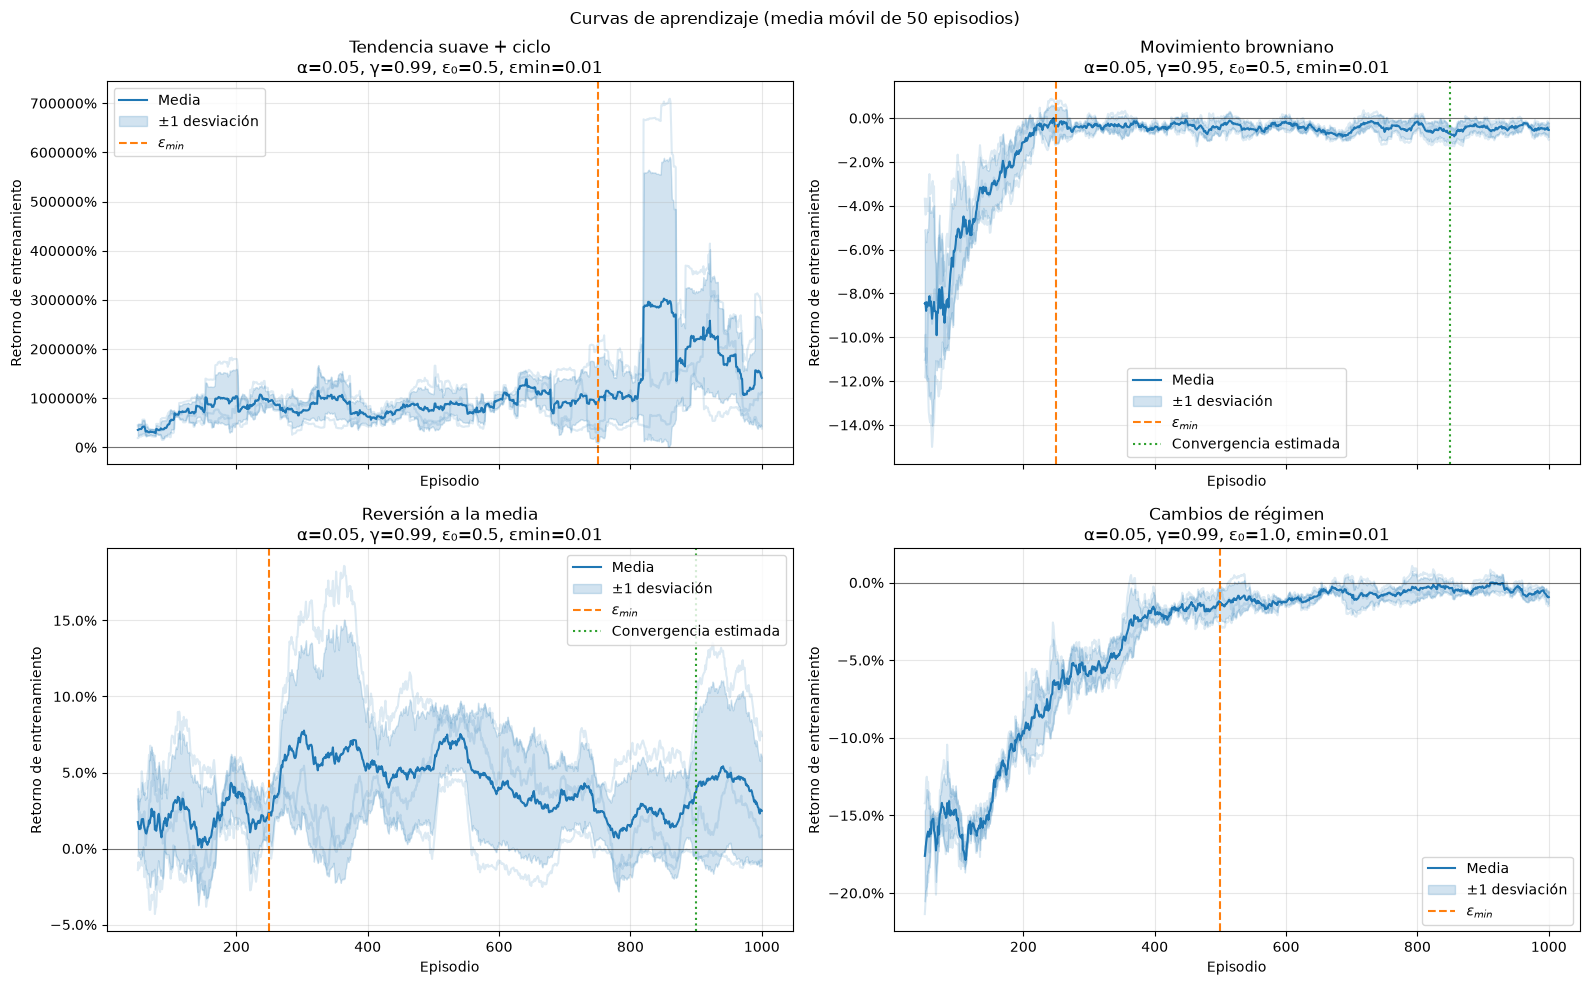

In [125]:
def moving_average(values, window):
    """Calcula una media móvil conservando solo ventanas completas."""
    values = np.asarray(values, dtype=np.float64)
    if values.ndim != 1:
        raise ValueError("values debe ser un vector")
    if not 1 <= window <= len(values):
        raise ValueError("window debe pertenecer a [1, len(values)]")

    kernel = np.ones(window, dtype=np.float64) / window
    return np.convolve(values, kernel, mode="valid")


def plot_best_learning_curves(results_by_generator, smoothing_window=50):
    """Representa la evolución del retorno de la mejor configuración."""
    if len(results_by_generator) == 0:
        raise ValueError("results_by_generator no puede estar vacío")

    figure, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
    axes = axes.ravel()

    for axis, (generator_name, results) in zip(
        axes, results_by_generator.items()
    ):
        if len(results) == 0:
            raise ValueError(f"no hay resultados para {generator_name}")

        best_result = results[0]
        config = best_result["configuration"]
        returns_by_seed = np.stack(
            [
                run["training_history"]["final_balances"]
                / run["training_history"]["initial_balance"]
                - 1.0
                for run in best_result["runs"]
            ]
        )
        smoothed_returns = np.stack(
            [
                moving_average(seed_returns, smoothing_window)
                for seed_returns in returns_by_seed
            ]
        )

        episodes = np.arange(smoothing_window, returns_by_seed.shape[1] + 1)
        mean_returns = np.mean(smoothed_returns, axis=0)
        std_returns = np.std(smoothed_returns, axis=0)

        for seed_returns in smoothed_returns:
            axis.plot(episodes, seed_returns, color="tab:blue", alpha=0.15)
        axis.plot(episodes, mean_returns, color="tab:blue", label="Media")
        axis.fill_between(
            episodes,
            mean_returns - std_returns,
            mean_returns + std_returns,
            color="tab:blue",
            alpha=0.20,
            label="±1 desviación",
        )

        exploration_end = round(
            config["n_episodes"] * config["exploration_fraction"]
        )
        axis.axvline(
            exploration_end,
            color="tab:orange",
            linestyle="--",
            label=r"$\epsilon_{min}$",
        )
        if best_result["mean_convergence_episode"] is not None:
            axis.axvline(
                best_result["mean_convergence_episode"],
                color="tab:green",
                linestyle=":",
                label="Convergencia estimada",
            )
        axis.axhline(0.0, color="black", linewidth=0.8, alpha=0.5)
        axis.set_title(
            f"{generator_name}\n"
            f"α={config['alpha']}, γ={config['gamma']}, "
            f"ε₀={config['epsilon']}, εmin={config['min_epsilon']}"
        )
        axis.set_xlabel("Episodio")
        axis.set_ylabel("Retorno de entrenamiento")
        axis.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
        axis.grid(True, alpha=0.3)
        axis.legend(loc="best")

    for unused_axis in axes[len(results_by_generator):]:
        unused_axis.set_visible(False)

    figure.suptitle(
        f"Curvas de aprendizaje (media móvil de {smoothing_window} episodios)"
    )
    figure.tight_layout()
    return figure, axes


learning_curves_figure, _ = plot_best_learning_curves(
    results_by_generator=grid_results_by_generator,
    smoothing_window=50,
)
plt.show()

### 10. Decisión sobre el número de episodios

Las curvas sugieren decisiones diferentes según el mercado:

- **Movimiento browniano:** el retorno de entrenamiento se estabiliza aproximadamente desde los episodios 250–300. Aunque el criterio automático sitúa la convergencia media en torno al episodio 850 y solo converge el 67 % de las semillas, los últimos cientos de episodios no muestran una mejora sostenida. Conservamos 1000 episodios.
- **Cambios de régimen:** la mejora principal termina aproximadamente entre los episodios 600 y 700, tras lo cual la curva permanece cerca de cero. La ausencia de convergencia automática en la configuración ganadora parece deberse a pequeñas oscilaciones, no a una tendencia ascendente. Conservamos 1000 episodios.
- **Reversión a la media:** la curva sigue siendo variable al final, la convergencia se detecta alrededor del episodio 900 y solo una de las tres semillas cumple el criterio. Repetimos la mejor configuración con 2000 episodios para comprobar si mejora su estabilidad.
- **Tendencia suave y ciclo:** los retornos alcanzan escalas de cientos de miles por ciento y presentan saltos muy grandes. El umbral absoluto de 0.5 puntos porcentuales no es comparable con los otros mercados. Antes de ampliar el entrenamiento aplicamos el mismo criterio usando cambios relativos del 5 % entre bloques.

Para el experimento de 2000 episodios recalculamos `epsilon_decay`, de forma que la exploración siga ocupando la misma fracción del entrenamiento que en la configuración seleccionada.

In [128]:
trend_generator_name = "Tendencia suave + ciclo"
trend_best_result = grid_results_by_generator[trend_generator_name][0]
trend_relative_convergence_episodes = []

for run in trend_best_result["runs"]:
    history = run["training_history"]
    convergence_episode = estimate_convergence_episode(
        final_balances=history["final_balances"],
        initial_balance=history["initial_balance"],
        block_size=50,
        change_threshold=0.05,
        stable_blocks=3,
        relative=True,
        scale_floor=0.01,
    )
    trend_relative_convergence_episodes.append(convergence_episode)

trend_converged_episodes = [
    episode
    for episode in trend_relative_convergence_episodes
    if episode is not None
]
trend_relative_convergence = {
    "episodes": tuple(trend_relative_convergence_episodes),
    "rate": len(trend_converged_episodes)
    / len(trend_relative_convergence_episodes),
    "mean_episode": (
        float(np.mean(trend_converged_episodes))
        if trend_converged_episodes
        else None
    ),
}

print("Convergencia relativa — Tendencia suave + ciclo:")
print(trend_relative_convergence)

Convergencia relativa — Tendencia suave + ciclo:
{'episodes': (None, None, None), 'rate': 0.0, 'mean_episode': None}


In [129]:
mean_reversion_name = "Reversión a la media"
mean_reversion_best_1000 = grid_results_by_generator[mean_reversion_name][0]
mean_reversion_config_2000 = {
    **mean_reversion_best_1000["configuration"],
    "n_episodes": 2000,
}
exploration_episodes_2000 = round(
    mean_reversion_config_2000["n_episodes"]
    * mean_reversion_config_2000["exploration_fraction"]
)
mean_reversion_config_2000["epsilon_decay"] = calculate_epsilon_decay(
    initial_epsilon=mean_reversion_config_2000["epsilon"],
    min_epsilon=mean_reversion_config_2000["min_epsilon"],
    episodes_until_minimum=exploration_episodes_2000,
)

mean_reversion_result_2000 = evaluate_hyperparameter_configuration(
    price_generator=price_generators[mean_reversion_name],
    configuration=mean_reversion_config_2000,
    training_seeds=(101, 202, 303),
    validation_dataset=validation_datasets_by_generator[mean_reversion_name],
    validation_seed=406,
    convergence_block_size=50,
    convergence_threshold=0.005,
    convergence_stable_blocks=3,
)

for episodes, result in (
    (1000, mean_reversion_best_1000),
    (2000, mean_reversion_result_2000),
):
    convergence = result["mean_convergence_episode"]
    convergence_text = (
        "no detectada" if convergence is None else f"{convergence:.0f}"
    )
    print(
        f"{episodes} episodios: "
        f"retorno_validación={result['mean_validation_return']:.4%}, "
        f"std_semillas={result['std_mean_return_between_seeds']:.4%}, "
        f"convergencia={convergence_text}, "
        f"tasa={result['convergence_rate']:.0%}"
    )

1000 episodios: retorno_validación=6.8834%, std_semillas=9.1555%, convergencia=900, tasa=33%
2000 episodios: retorno_validación=0.0000%, std_semillas=0.0000%, convergencia=1850, tasa=33%


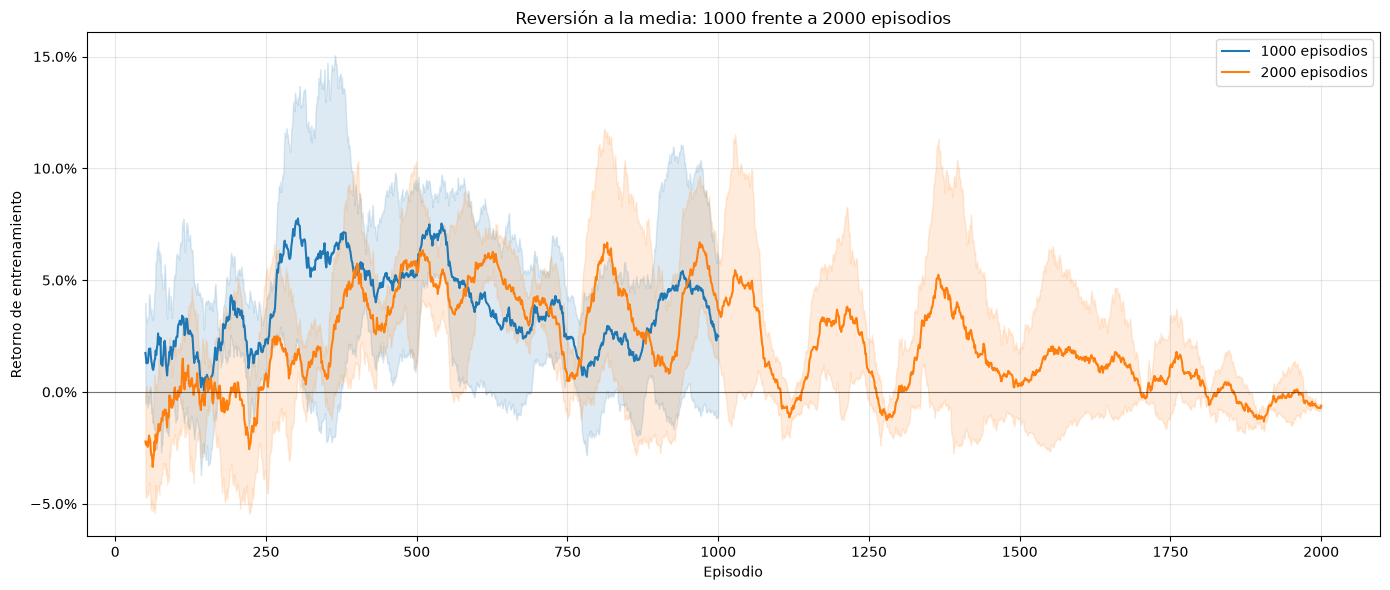

In [130]:
def plot_training_length_comparison(
    result_1000,
    result_2000,
    smoothing_window=50,
):
    """Compara las curvas de entrenamiento de 1000 y 2000 episodios."""
    figure, axis = plt.subplots(figsize=(14, 6))
    colors = {1000: "tab:blue", 2000: "tab:orange"}

    for episodes, result in ((1000, result_1000), (2000, result_2000)):
        returns_by_seed = np.stack(
            [
                run["training_history"]["final_balances"]
                / run["training_history"]["initial_balance"]
                - 1.0
                for run in result["runs"]
            ]
        )
        smoothed_returns = np.stack(
            [
                moving_average(seed_returns, smoothing_window)
                for seed_returns in returns_by_seed
            ]
        )
        x = np.arange(smoothing_window, episodes + 1)
        mean_returns = np.mean(smoothed_returns, axis=0)
        std_returns = np.std(smoothed_returns, axis=0)
        color = colors[episodes]

        axis.plot(x, mean_returns, color=color, label=f"{episodes} episodios")
        axis.fill_between(
            x,
            mean_returns - std_returns,
            mean_returns + std_returns,
            color=color,
            alpha=0.15,
        )

    axis.axhline(0.0, color="black", linewidth=0.8, alpha=0.5)
    axis.set_title("Reversión a la media: 1000 frente a 2000 episodios")
    axis.set_xlabel("Episodio")
    axis.set_ylabel("Retorno de entrenamiento")
    axis.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    axis.grid(True, alpha=0.3)
    axis.legend()
    figure.tight_layout()
    return figure, axis


training_length_figure, _ = plot_training_length_comparison(
    result_1000=mean_reversion_best_1000,
    result_2000=mean_reversion_result_2000,
)
plt.show()

#### Conclusión sobre la duración del entrenamiento

El experimento adicional muestra que aumentar de 1000 a 2000 episodios no mejora la mejor configuración de reversión a la media. Con 2000 episodios, las tres semillas terminan con un retorno medio de validación del 0 %, frente al 6.8834 % obtenido por la configuración seleccionada con 1000 episodios. Solo una semilla cumple el criterio de convergencia, en el episodio 1850, por lo que la tasa sigue siendo del 33 %. El entrenamiento adicional conduce en este caso a una política conservadora que permanece en efectivo.

Para tendencia suave y ciclo, el criterio relativo del 5 % tampoco detecta convergencia en ninguna de las tres semillas. Dado que la curva contiene saltos extremos y retornos de una escala extraordinariamente alta, esto apunta a la inestabilidad del generador y de la distribución de retornos, no simplemente a una falta de episodios.

En consecuencia, mantenemos 1000 episodios para los cuatro generadores. Browniano y cambios de régimen ya muestran una meseta visual; reversión a la media empeora al ampliar el entrenamiento; y tendencia+ciclo requiere revisar la escala o la definición del generador antes de justificar más episodios.

## Evaluación final sobre test

La selección de hiperparámetros ha terminado. Generamos ahora, para cada mercado, un conjunto de test de 200 series nuevas con semillas distintas de las utilizadas en entrenamiento y validación. Estos datos se usan una sola vez para estimar el rendimiento final y no influyen en la elección del modelo.

Evaluamos las tres tablas Q de la configuración ganadora —una por semilla de entrenamiento— y agregamos todos sus retornos. Las estrategias de efectivo y buy & hold se ejecutan sobre exactamente las mismas series. El episodio y el tiempo de convergencia proceden del entrenamiento de Q-learning; no son aplicables a los baselines, que no necesitan aprendizaje.

In [132]:
def evaluate_best_configuration_on_test(
    best_result,
    test_dataset,
    test_seed=0,
):
    """Evalúa en test todas las tablas Q entrenadas de una configuración."""
    if len(best_result["runs"]) == 0:
        raise ValueError("best_result no contiene entrenamientos")

    discretizer = StateDiscretizer()
    evaluations = []
    evaluation_start = perf_counter()

    for run in best_result["runs"]:
        evaluations.append(
            evaluate_q_table(
                q_table=run["q_table"],
                discretizer=discretizer,
                price_dataset=test_dataset,
                seed=test_seed,
            )
        )

    evaluation_seconds = perf_counter() - evaluation_start
    returns = np.stack(
        [evaluation["returns"] for evaluation in evaluations]
    )
    final_balances = np.stack(
        [evaluation["final_balances"] for evaluation in evaluations]
    )

    return {
        "evaluations": tuple(evaluations),
        "returns": returns,
        "final_balances": final_balances,
        "mean_return": float(np.mean(returns)),
        "std_return": float(np.std(returns)),
        "mean_final_balance": float(np.mean(final_balances)),
        "evaluation_seconds": evaluation_seconds,
    }

In [133]:
test_datasets_by_generator = {}
test_results_by_generator = {}
test_comparison_rows = []

for generator_index, (generator_name, price_generator) in enumerate(
    price_generators.items()
):
    test_dataset = generate_price_dataset(
        price_generator=price_generator,
        n_series=200,
        n_steps=500,
        seed=10_000 + generator_index,
    )
    test_datasets_by_generator[generator_name] = test_dataset

    best_result = grid_results_by_generator[generator_name][0]
    q_learning_test = evaluate_best_configuration_on_test(
        best_result=best_result,
        test_dataset=test_dataset,
        test_seed=20_000 + generator_index,
    )
    baselines_test = evaluate_baselines(
        price_dataset=test_dataset,
        seed=20_000 + generator_index,
    )
    test_results_by_generator[generator_name] = {
        "q_learning": q_learning_test,
        **baselines_test,
    }

    config = best_result["configuration"]
    test_comparison_rows.append(
        {
            "generator": generator_name,
            "model": "Q-learning",
            "n_episodes": config["n_episodes"],
            "n_steps": config["n_steps"],
            "alpha": config["alpha"],
            "gamma": config["gamma"],
            "epsilon": config["epsilon"],
            "epsilon_decay": config["epsilon_decay"],
            "min_epsilon": config["min_epsilon"],
            "exploration_fraction": config["exploration_fraction"],
            "mean_return": q_learning_test["mean_return"],
            "std_return": q_learning_test["std_return"],
            "convergence_episode": best_result["mean_convergence_episode"],
            "convergence_seconds": best_result["mean_convergence_seconds"],
            "convergence_rate": best_result["convergence_rate"],
        }
    )

    for baseline_key, baseline_name in (
        ("cash", "Efectivo"),
        ("buy_and_hold", "Buy & Hold"),
    ):
        baseline_result = baselines_test[baseline_key]
        test_comparison_rows.append(
            {
                "generator": generator_name,
                "model": baseline_name,
                "n_episodes": None,
                "n_steps": None,
                "alpha": None,
                "gamma": None,
                "epsilon": None,
                "epsilon_decay": None,
                "min_epsilon": None,
                "exploration_fraction": None,
                "mean_return": baseline_result["mean_return"],
                "std_return": baseline_result["std_return"],
                "convergence_episode": None,
                "convergence_seconds": None,
                "convergence_rate": None,
            }
        )

In [134]:
def display_test_comparison_table(rows):
    """Muestra los resultados finales como una tabla Markdown."""
    headers = (
        "Generador",
        "Modelo",
        "Episodios",
        "Pasos",
        "α",
        "γ",
        "ε₀",
        "ε decay",
        "εmin",
        "Frac. exploración",
        "Retorno test",
        "Desv. test",
        "Conv. episodios",
        "Conv. segundos",
        "Tasa conv.",
    )
    table = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]

    for row in rows:
        is_q_learning = row["model"] == "Q-learning"
        if is_q_learning:
            convergence_episode = (
                "No detectada"
                if row["convergence_episode"] is None
                else f"{row['convergence_episode']:.0f}"
            )
            convergence_seconds = (
                "No detectada"
                if row["convergence_seconds"] is None
                else f"{row['convergence_seconds']:.1f}"
            )
            convergence_rate = f"{row['convergence_rate']:.0%}"
            parameters = (
                str(row["n_episodes"]),
                str(row["n_steps"]),
                f"{row['alpha']:.2f}",
                f"{row['gamma']:.2f}",
                f"{row['epsilon']:.2f}",
                f"{row['epsilon_decay']:.6f}",
                f"{row['min_epsilon']:.2f}",
                f"{row['exploration_fraction']:.2f}",
            )
        else:
            convergence_episode = "N/A"
            convergence_seconds = "N/A"
            convergence_rate = "N/A"
            parameters = (
                "—", "—", "—", "—",
                "—", "—", "—", "—",
            )

        values = (
            row["generator"],
            row["model"],
            *parameters,
            f"{row['mean_return']:.4%}",
            f"{row['std_return']:.4%}",
            convergence_episode,
            convergence_seconds,
            convergence_rate,
        )
        table.append("| " + " | ".join(values) + " |")

    display(Markdown("\n".join(table)))


display_test_comparison_table(test_comparison_rows)

| Generador | Modelo | Episodios | Pasos | α | γ | ε₀ | ε decay | εmin | Frac. exploración | Retorno test | Desv. test | Conv. episodios | Conv. segundos | Tasa conv. |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Tendencia suave + ciclo | Q-learning | 1000 | 500 | 0.05 | 0.99 | 0.50 | 0.994798 | 0.01 | 0.75 | 265285.8683% | 921942.0641% | No detectada | No detectada | 0% |
| Tendencia suave + ciclo | Efectivo | — | — | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | N/A | N/A |
| Tendencia suave + ciclo | Buy & Hold | — | — | — | — | — | — | — | — | 32227.7832% | 114455.1962% | N/A | N/A | N/A |
| Movimiento browniano | Q-learning | 1000 | 500 | 0.05 | 0.95 | 0.50 | 0.984474 | 0.01 | 0.25 | 0.0020% | 0.0478% | 850 | 5.6 | 67% |
| Movimiento browniano | Efectivo | — | — | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | N/A | N/A |
| Movimiento browniano | Buy & Hold | — | — | — | — | — | — | — | — | 5.6357% | 48.8999% | N/A | N/A | N/A |
| Reversión a la media | Q-learning | 1000 | 500 | 0.05 | 0.99 | 0.50 | 0.984474 | 0.01 | 0.25 | 5.7648% | 15.5831% | 900 | 5.9 | 33% |
| Reversión a la media | Efectivo | — | — | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | N/A | N/A |
| Reversión a la media | Buy & Hold | — | — | — | — | — | — | — | — | -0.4499% | 8.0018% | N/A | N/A | N/A |
| Cambios de régimen | Q-learning | 1000 | 500 | 0.05 | 0.99 | 1.00 | 0.990832 | 0.01 | 0.50 | 0.0086% | 0.5169% | No detectada | No detectada | 0% |
| Cambios de régimen | Efectivo | — | — | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | N/A | N/A |
| Cambios de régimen | Buy & Hold | — | — | — | — | — | — | — | — | -8.3960% | 42.1356% | N/A | N/A | N/A |